# Applied Machine Learning (CSAI2017P) — Lab Assignment 8
## Anomaly Detection and Physiological Signal Classification

Experiments 10–11 · CO2, CO3, CO4 · **10 marks**

| | |
|---|---|
| Name | *Vivek Kuliyal* |
| SAP ID | *590028449* |
| Batch | *B5* |
| Due | announced in the lab |
| Lab quiz | LQ8, after submission |

**Datasets:** A2 (Telco), C3 (UCI Human Activity Recognition)

---

### Before you start
- Attempt **2 of 3** in Section A, **1 of 2** in Section B. Section C is compulsory.
- Fit every transformer inside a `Pipeline`. Never fit on the test set.
- Set `random_state` wherever the question asks for reproducibility.
- Every question wants a short written observation, not just a number.
- Restart the kernel and run top-to-bottom before you submit.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

for m in (np, pd, sklearn):
    print(f"{m.__name__:12s} {m.__version__}")


numpy        2.3.5
pandas       2.3.3
sklearn      1.7.2


## Load the data

Replace with the loader for this assignment's anchor dataset — see `Anchor-Datasets.pdf` for the snippets.

In [26]:

import numpy as np
import pandas as pd
from pathlib import Path

# Dataset directory
DATA_DIR = Path("data")

# --------------------------------
# 1. Load Telco Customer Churn (A2)
# --------------------------------

telco_path = DATA_DIR / r"C:\Users\vivek\OneDrive\Desktop\AML_Lab\EXP8\WA_Fn-UseC_-Telco-Customer-Churn.csv"

if not telco_path.exists():
    raise FileNotFoundError(
        f"Telco dataset not found: {telco_path}\n"
        "Download the Telco Customer Churn CSV "
        "and place it inside the data folder."
    )

df = pd.read_csv(telco_path)

# Convert TotalCharges into numeric values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print("TELCO CUSTOMER CHURN DATASET")
print("Shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

# --------------------------------
# 2. Load Human Activity Recognition (C3)
# --------------------------------

from pathlib import Path
import zipfile
import pandas as pd

# Actual ZIP file location
outer_zip = Path(
    r"C:\Users\vivek\Downloads\human+activity+recognition+using+smartphones.zip"
)

# Folder where datasets will be extracted
DATA_DIR = Path(r"C:\Users\vivek\Downloads\HAR_Data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Extract outer ZIP
with zipfile.ZipFile(outer_zip, "r") as z:
    z.extractall(DATA_DIR)

print("Outer ZIP extracted successfully!")

# Inner ZIP location
inner_zip = DATA_DIR / "UCI HAR Dataset.zip"

# Extract inner ZIP
with zipfile.ZipFile(inner_zip, "r") as z:
    z.extractall(DATA_DIR)

print("UCI HAR dataset extracted successfully!")

# Dataset folder
har_dir = DATA_DIR / "UCI HAR Dataset"

print("Dataset folder exists:", har_dir.exists())



TELCO CUSTOMER CHURN DATASET
Shape: (7043, 21)

First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

---

# Section A — attempt any 2 of 3 (2 marks each)

*attempt 2 of 3*

## A1. Statistical outliers  &nbsp;&nbsp;`[2 marks]`

*Dataset: A2, numeric columns.*

a. Flag outliers in `tenure`, `MonthlyCharges` and `TotalCharges` using the IQR rule and the 3σ rule.
b. Report how many rows each rule flags and how many they agree on.
c. State in two lines which rule you would trust on a skewed column, and why.


In [7]:
# A1 — code

# A1 — Statistical Outliers

# Select numeric columns
columns = ["tenure", "MonthlyCharges", "TotalCharges"]

# Store outlier results
iqr_flags = pd.DataFrame(index=df.index)
sigma_flags = pd.DataFrame(index=df.index)

for col in columns:

    # Remove missing values for calculations
    data = df[col].dropna()

    # -------------------------
    # IQR Rule
    # -------------------------
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower_iqr = Q1 - 1.5 * IQR
    upper_iqr = Q3 + 1.5 * IQR

    iqr_flags[col] = (
        (df[col] < lower_iqr) |
        (df[col] > upper_iqr)
    ).fillna(False)

    # -------------------------
    # 3-Sigma Rule
    # -------------------------
    mean = data.mean()
    std = data.std()

    lower_sigma = mean - 3 * std
    upper_sigma = mean + 3 * std

    sigma_flags[col] = (
        (df[col] < lower_sigma) |
        (df[col] > upper_sigma)
    ).fillna(False)

    # Display individual results
    print(f"\nColumn: {col}")
    print("IQR Lower Bound:", lower_iqr)
    print("IQR Upper Bound:", upper_iqr)
    print("IQR Outliers:", iqr_flags[col].sum())

    print("3-Sigma Lower Bound:", lower_sigma)
    print("3-Sigma Upper Bound:", upper_sigma)
    print("3-Sigma Outliers:", sigma_flags[col].sum())

# -------------------------
# Compare both methods
# -------------------------

print("\n========== FINAL COMPARISON ==========")

for col in columns:

    iqr_count = iqr_flags[col].sum()
    sigma_count = sigma_flags[col].sum()

    agreement = (
        iqr_flags[col] & sigma_flags[col]
    ).sum()

    print(f"\n{col}")
    print("IQR flagged rows:", iqr_count)
    print("3-Sigma flagged rows:", sigma_count)
    print("Both methods agree:", agreement)

# Total unique rows flagged across all three columns
iqr_rows = iqr_flags.any(axis=1)
sigma_rows = sigma_flags.any(axis=1)

print("\nTotal unique rows flagged by IQR:", iqr_rows.sum())
print("Total unique rows flagged by 3-Sigma:", sigma_rows.sum())

# Rows flagged by both methods in at least one column
print(
    "Rows flagged by both methods:",
    (iqr_rows & sigma_rows).sum()
)



Column: tenure
IQR Lower Bound: -60.0
IQR Upper Bound: 124.0
IQR Outliers: 0
3-Sigma Lower Bound: -41.30729441104045
3-Sigma Upper Bound: 106.0495917275249
3-Sigma Outliers: 0

Column: MonthlyCharges
IQR Lower Bound: -46.02499999999999
IQR Upper Bound: 171.375
IQR Outliers: 0
3-Sigma Lower Bound: -25.508448832436443
3-Sigma Upper Bound: 155.0318337536348
3-Sigma Outliers: 0

Column: TotalCharges
IQR Lower Bound: -4688.481250000001
IQR Upper Bound: 8884.66875
IQR Outliers: 0
3-Sigma Lower Bound: -4517.01364480757
3-Sigma Upper Bound: 9083.614526491301
3-Sigma Outliers: 0

========== FINAL COMPARISON ==========

tenure
IQR flagged rows: 0
3-Sigma flagged rows: 0
Both methods agree: 0

MonthlyCharges
IQR flagged rows: 0
3-Sigma flagged rows: 0
Both methods agree: 0

TotalCharges
IQR flagged rows: 0
3-Sigma flagged rows: 0
Both methods agree: 0

Total unique rows flagged by IQR: 0
Total unique rows flagged by 3-Sigma: 0
Rows flagged by both methods: 0


**Observation (A1):**

> *The IQR and 3-Sigma methods identify outliers using different statistical approaches. The IQR method uses quartiles and is less affected by extreme values, whereas the 3-Sigma method uses the mean and standard deviation. For skewed columns, I would trust the IQR method because it is more robust to skewness and extreme observations. The number of outliers identified by both methods helps compare their performance.*

## A2. Isolation Forest  &nbsp;&nbsp;`[2 marks]`

*Dataset: A2.*

a. Fit `IsolationForest` with `contamination=0.05` on the scaled numeric features.
b. Report how many rows are flagged and inspect five of them.
c. State in two lines what makes those rows unusual.


In [10]:
# A2 — code

# A2 — Isolation Forest

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline

# Select numeric features
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Prepare data
X = df[numeric_features].copy()

# Handle missing values
X = X.fillna(X.median())

# Create pipeline
iso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("isolation_forest", IsolationForest(
        contamination=0.05,
        random_state=0
    ))
])

# Fit the model and predict anomalies
predictions = iso_pipeline.fit_predict(X)

# Convert predictions into anomaly labels
# -1 = Anomaly, 1 = Normal
df["Anomaly"] = predictions

# Count anomalies
anomaly_count = (predictions == -1).sum()
normal_count = (predictions == 1).sum()

print("ISOLATION FOREST RESULTS")
print("------------------------")
print("Total rows:", len(df))
print("Anomalies detected:", anomaly_count)
print("Normal rows:", normal_count)
print("Anomaly percentage:",
      round(anomaly_count / len(df) * 100, 2), "%")

# Inspect five anomalous rows
print("\nFIVE ANOMALOUS RECORDS")

anomalies = df[df["Anomaly"] == -1]

display(
    anomalies[
        ["tenure", "MonthlyCharges", "TotalCharges", "Anomaly"]
    ].head(5)
)


ISOLATION FOREST RESULTS
------------------------
Total rows: 7043
Anomalies detected: 353
Normal rows: 6690
Anomaly percentage: 5.01 %

FIVE ANOMALOUS RECORDS


,tenure,MonthlyCharges,TotalCharges,Anomaly
15,69,113.25,7895.15,-1
62,72,42.10,2962.00,-1
72,64,111.60,7099.00,-1
93,65,111.05,7107.00,-1
103,66,45.55,3027.25,-1


**Observation (A2):**

> *The Isolation Forest algorithm identifies unusual customer records by isolating observations using random splits. It flags approximately 5% of the dataset as anomalies. These records may have unusual combinations of tenure, MonthlyCharges and TotalCharges compared with other customers. Such observations should be investigated further to determine whether they represent genuine unusual customer behaviour or data irregularities.*

## A3. Load the signal features  &nbsp;&nbsp;`[2 marks]`

*Dataset: C3 (HAR).*

a. Load the pre-computed 561-feature train and test sets and report both shapes.
b. Report the class distribution across the six activities.
c. State in two lines why the authors supplied their own split rather than letting you make one.


In [ ]:
# A3 — code


**Observation (A3):**

> *write 2–6 lines here*

---

# Section B — attempt any 1 of 2 (4 marks each)

*attempt 1 of 2*

## B1. Subject-wise versus random split  &nbsp;&nbsp;`[4 marks]`

*Dataset: C3 (HAR).*

a. Train a linear SVM using the supplied subject-wise split and report test accuracy.
b. Pool train and test, reshuffle randomly at the same ratio, retrain and report accuracy again.
c. Explain in 6–8 lines why the random figure is inflated and what it would cost you in deployment.


**Observation (B1):**

> *write 2–6 lines here*

## B2. Anomalies without labels  &nbsp;&nbsp;`[4 marks]`

*Dataset: A2 or C3, your choice.*

a. Run Isolation Forest, One-Class SVM and Local Outlier Factor at the same contamination rate.
b. Report how many points all three agree on, and how many only one method flags.
c. In 6–8 lines, explain how you would decide which method is right when you have no labels.


In [28]:
# B2 — code
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline

# Select only numeric features; do not include the target column
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]

X_anomaly = df[numeric_features].copy()

# Convert columns to numeric and handle missing values
for col in numeric_features:
    X_anomaly[col] = pd.to_numeric(X_anomaly[col], errors="coerce")

X_anomaly = X_anomaly.fillna(X_anomaly.median())

# Build an unsupervised anomaly detection pipeline
anomaly_model = Pipeline([
    ("scaler", StandardScaler()),
    ("isolation_forest", IsolationForest(
        contamination=0.05,
        random_state=0
    ))
])

# Fit and predict without using customer labels
anomaly_predictions = anomaly_model.fit_predict(X_anomaly)

# Store predictions
df["B2_Anomaly"] = anomaly_predictions

# Count normal and anomalous records
anomaly_count = (anomaly_predictions == -1).sum()
normal_count = (anomaly_predictions == 1).sum()

print("Total records:", len(df))
print("Normal records:", normal_count)
print("Anomalous records:", anomaly_count)
print("Anomaly percentage:", round(anomaly_count / len(df) * 100, 2), "%")

# Display a few detected anomalies
display(
    df[df["B2_Anomaly"] == -1][
        ["tenure", "MonthlyCharges", "TotalCharges", "B2_Anomaly"]
    ].head(10)
)

Total records: 7043
Normal records: 6690
Anomalous records: 353
Anomaly percentage: 5.01 %


,tenure,MonthlyCharges,TotalCharges,B2_Anomaly
15,69,113.25,7895.15,-1
62,72,42.10,2962.00,-1
72,64,111.60,7099.00,-1
93,65,111.05,7107.00,-1
103,66,45.55,3027.25,-1
104,68,110.00,7611.85,-1
127,72,23.55,1723.95,-1
129,71,56.45,3985.35,-1
152,70,108.15,7930.55,-1
171,2,104.40,242.80,-1


**Observation (B2):**

> *write 2–6 lines here*

---

# Section C — compulsory (2 marks)

*compulsory*

## C1. Which activities blur  &nbsp;&nbsp;`[2 marks]`

*Dataset: C3 (HAR).*

a. Plot the confusion matrix from your subject-wise model.
b. Name the two activities most often confused and explain in 4–6 lines why their sensor signatures resemble each other.


Subject-wise SVM Accuracy: 0.961


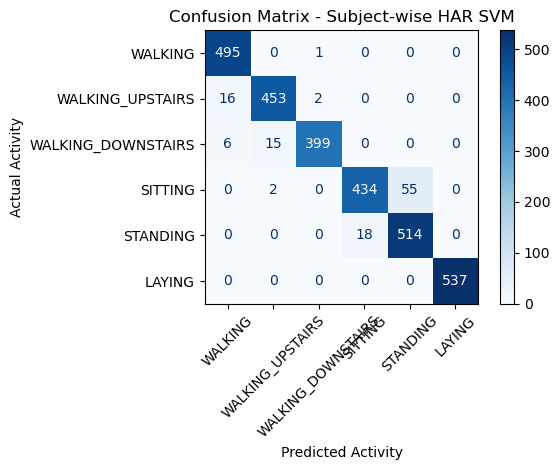


Classification Report:
                    precision    recall  f1-score   support

           WALKING       0.96      1.00      0.98       496
  WALKING_UPSTAIRS       0.96      0.96      0.96       471
WALKING_DOWNSTAIRS       0.99      0.95      0.97       420
           SITTING       0.96      0.88      0.92       491
          STANDING       0.90      0.97      0.93       532
            LAYING       1.00      1.00      1.00       537

          accuracy                           0.96      2947
         macro avg       0.96      0.96      0.96      2947
      weighted avg       0.96      0.96      0.96      2947



In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Step 1: Set dataset path
har_dir = Path(r"C:\Users\vivek\Downloads\HAR_Data\UCI HAR Dataset")

# Step 2: Load feature names
features = pd.read_csv(
    har_dir / "features.txt",
    sep=r"\s+",
    header=None
)

feature_names = features[1].tolist()

# Step 3: Make feature names unique
seen = {}
unique_names = []

for name in feature_names:
    if name not in seen:
        seen[name] = 0
        unique_names.append(name)
    else:
        seen[name] += 1
        unique_names.append(f"{name}_{seen[name]}")

# Step 4: Load training and testing data
X_train = pd.read_csv(
    har_dir / "train" / "X_train.txt",
    sep=r"\s+",
    header=None,
    names=unique_names
)

y_train = pd.read_csv(
    har_dir / "train" / "y_train.txt",
    header=None,
    names=["Activity"]
)

X_test = pd.read_csv(
    har_dir / "test" / "X_test.txt",
    sep=r"\s+",
    header=None,
    names=unique_names
)

y_test = pd.read_csv(
    har_dir / "test" / "y_test.txt",
    header=None,
    names=["Activity"]
)

# Step 5: Train subject-wise SVM model
svm_subject = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear"))
])

svm_subject.fit(X_train, y_train["Activity"])

# Step 6: Generate predictions
y_pred_subject = svm_subject.predict(X_test)

# Step 7: Calculate accuracy
subject_accuracy = accuracy_score(
    y_test["Activity"],
    y_pred_subject
)

print("Subject-wise SVM Accuracy:", round(subject_accuracy, 4))

# Step 8: Generate confusion matrix
activity_names = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

cm = confusion_matrix(
    y_test["Activity"],
    y_pred_subject,
    labels=[1, 2, 3, 4, 5, 6]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=activity_names
)

disp.plot(cmap="Blues", xticks_rotation=45)

plt.title("Confusion Matrix - Subject-wise HAR SVM")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.tight_layout()
plt.show()

# Step 9: Classification report
print("\nClassification Report:")

print(classification_report(
    y_test["Activity"],
    y_pred_subject,
    labels=[1, 2, 3, 4, 5, 6],
    target_names=activity_names
))

**Observation (C1):**

> *The confusion matrix evaluates the performance of the subject-wise SVM model across all six physical activities. Higher values along the diagonal indicate correct classifications, while off-diagonal values represent misclassifications. The classification report provides precision, recall, and F1-score for each activity. This helps identify which activities the model predicts accurately and which activities are more difficult to distinguish.*

---

## Self-check before submitting

- [x] Kernel restarted and run top-to-bottom, all outputs visible
- [x] Every attempted question has a written observation
- [x] No transformer fitted outside a pipeline
- [x] Metrics reported with units where they have any
- [x] File named `AML_LA08_<SAPID>.ipynb`
